# Matching: Leadership in Social Movements

ECON526 — Real-Data Application (Dippel & Heblich, 2021)

Paul Schrimpf (University of British Columbia)

# Introduction

## Research Question & Setting

- **Paper:** Dippel and Heblich (2021), *“Leadership in Social
  Movements: Evidence from the ‘Forty-Eighters’ in the Civil War”*,
  *American Economic Review*, 111(2): 472–505.
- **Historical setting:** Exiled leaders of the failed 1848–1849 German
  revolution (“Forty-Eighters”) settled in U.S. towns and campaigned
  against slavery.
- **Treatment ($D_i \in \{0, 1\}$):** `fourty8ersD_1856` — whether town
  $i$ had at least one Forty-Eighter by 1856.
- **Outcome ($Y_i$):** `logenlistments` — log Union Army enlistments
  from town $i$ during the U.S. Civil War.
- **Covariates ($X_i$):** Pre-treatment town demographics (1840–1850),
  German-born share, geography, climate, and state indicators.

This real-data example examines whether grassroots leaders can causally
shift collective action and political mobilization. In 1848–1849, a wave
of liberal and democratic revolutions swept across the German states.
After the revolutions failed, many of the intellectual and political
leaders—known as the “Forty-Eighters”—fled to the United States, where
they became outspoken abolitionists, newspaper editors, and community
organizers.

The empirical challenge is that Forty-Eighters did not settle in U.S.
towns at random. They tended to locate in larger towns that already had
sizable German-born populations, German newspapers, or favorable
geographic access. If those same town characteristics also made
residents more (or less) likely to enlist in the Union Army during the
Civil War, a simple comparison of towns with and without Forty-Eighters
would confound the effect of leadership with pre-existing town
differences.

To address this selection problem using matching, we rely on the
**Conditional Independence Assumption (CIA)** (selection on
observables): $$
(Y_i(0), Y_i(1)) \perp D_i \mid X_i
$$ together with **overlap** (positivity): $$
0 < P(D_i = 1 \mid X_i) < 1 \quad \text{almost surely.}
$$ In words, conditional on observed pre-treatment town characteristics
$X_i$, whether a town received a Forty-Eighter is treated as
as-good-as-random, and every type of town has a strictly positive
probability of being treated or untreated.

## Empirical Strategy Overview

- **Why not just OLS?**
  - Linear regression
    $Y_i = \hat{\alpha} D_i + X_i'\hat{\beta} + \hat{\epsilon}_i$
    imposes linearity and weights observations by
    $\omega(D_i, X_i) \propto D_i - X_i'\pi$, which can be negative!
- **Original paper’s approach:**
  - Estimates a propensity score
    $\hat{p}(X_i) = \hat{P}(D_i = 1 \mid X_i)$.
  - Uses **5-nearest-neighbor propensity score matching with
    replacement** (exact-matched within state and town-size bins) to
    construct a matched sample, then estimates treatment effects on the
    matched sample.
- **Modern `doubleml` approaches:**
  - **Interactive Regression Model (`DoubleMLIRM`)** for doubly robust
    ATTE estimation.
  - **Partially Linear Regression (`DoubleMLPLR`)** when treatment is
    rare ($0.66\%$ treated) and inverse propensity weights become
    unstable.

Comparing these estimators on the same dataset illustrates both the
strengths and the practical pitfalls of matching methods:

1.  **OLS** is easy to run, but by the Frisch-Waugh-Lovell theorem it
    recovers a variance-weighted average of treatment effects where the
    implicit weights
    $\omega(D_i, X_i) = (D_i - X_i'\pi) / \mathbb{E}[(D_i - X_i'\pi)^2]$
    depend on a linear approximation to $\mathbb{E}[D_i \mid X_i]$. When
    $D_i$ is rare and nonlinear in $X_i$, OLS extrapolates across
    non-overlapping towns and can assign negative weights to treated
    units.
2.  **Nearest-neighbor propensity score matching** (Dippel and
    Heblich 2021) directly pairs each of the 73 treated towns with 5
    similar control towns, focusing on the **Average Treatment Effect on
    the Treated (ATT)** and trimming away the thousands of tiny,
    incomparable control towns.
3.  **`DoubleMLIRM` vs. `DoubleMLPLR`** (Chernozhukov et al. 2018): In
    `site/matching.qmd`, `DoubleMLIRM` worked smoothly because roughly
    33% of students were treated and overlap was strong. Here, only **73
    out of 11,096 towns (0.66%)** are treated! We will see directly what
    happens to `DoubleMLIRM` when propensity scores approach 0 and 1—and
    why `DoubleMLPLR` (partialling out without dividing by
    $m_0(X)(1-m_0(X))$) remains stable.

# Data Preparation

## Loading & Merging the Replication Files

In [1]:
import os
import numpy as np
import pandas as pd
from matplotlib import style
from matplotlib import pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

style.use("fivethirtyeight")
pd.set_option("display.max_columns", 25)

din = "./data/REPLICATION/data_in"

In [2]:
# Replicate the town-level dataset construction from REPLICATION/code/build_main.do
df = pd.read_stata(os.path.join(din, "master_haines.dta"))

# Town size bins (bottom 5%, middle 90%, top 5%) used for exact matching in the paper
p95, p05 = df["lnpop50"].quantile([0.95, 0.05])
df["fe_lnpop_pct"] = 1
df.loc[df["lnpop50"] >= p95, "fe_lnpop_pct"] = 2
df.loc[df["lnpop50"] <= p05, "fe_lnpop_pct"] = 3

# Merge town-level datasets on (name, county_icpsr, state_icpsr)
town_files = [
    "FourtyEighters_town.dta", "FourtyEighters_from1856.dta", "enlistments_town.dta",
    "enlistmentsInterpolated.dta", "turnvereine_towns.dta", "newspapersGerman_town.dta",
    "germans_bytownFullCount.dta", "ShiplistsGermans.dta", "others_bytownFullCount.dta",
    "geo_controls.dta", "1840_towns.dta",
]
for fname in town_files:
    sub = pd.read_stata(os.path.join(din, fname))
    df = df.merge(sub, on=["name", "county_icpsr", "state_icpsr"], how="outer")

# Merge county-level controls on (state_icpsr, county_icpsr)
for fname in ["ipums_countycontrols.dta", "votingdata_co_xs.dta"]:
    sub = pd.read_stata(os.path.join(din, fname))
    df = df.merge(sub, on=["state_icpsr", "county_icpsr"], how="left")

/tmp/ipykernel_393536/1443117678.py:2: UnicodeWarning: 
One or more strings in the dta file could not be decoded using utf-8, and
so the fallback encoding of latin-1 is being used.  This can happen when a file
has been incorrectly encoded by Stata or some other software. You should verify
the string values returned are correct.
  df = pd.read_stata(os.path.join(din, "master_haines.dta"))

The replication archive for Dippel & Heblich (2021) stores
raw/intermediate datasets in Stata `.dta` format inside
`REPLICATION/data_in/` and builds the analysis file via
`REPLICATION/code/build_main.do`. Here we translate `build_main.do`
directly into Python using `pandas.read_stata`.

The unit of observation is a U.S. town/city (identified by `name`,
`county_icpsr`, and `state_icpsr`). Notice how `build_main.do` also
constructs `fe_lnpop_pct`, a 3-category indicator for whether a town is
in the bottom 5%, middle 90%, or top 5% of the 1850 log-population
distribution. In the paper’s main matching specification (`PSM1_`), each
treated town is matched only to control towns in the **same state** and
**same population-size bin**.

## Defining Treatment, Outcome, and Covariates

In [3]:
# Construct outcome and German-born share variables as in build_main.do
df["enlistments"] = df["count_1"]
df["logenlistments"] = np.log(df["enlistments"].where(df["enlistments"] > 0))
df["gborn1850_share"] = (df["count_gborn1850"] / df["pop50"]).fillna(0)
df["gborn1860_share"] = (df["count_gborn1860"] / df["pop60"]).fillna(0)
df["ch_gborn_share"] = (df["gborn1860_share"] - df["gborn1850_share"]).fillna(0)

# Drop Western/Southern states (no Union enlistment data) and NYC (>100 Forty-Eighters)
df = df[~df["region"].isin(["west", "deepsouth", "oldsouth"])].copy()
df = df[~(df["fourty8ers"] > 100)].copy()

# Exact control groups from REPLICATION/code/Master_do.do
D_col = "fourty8ersD_1856"
Y_col = "logenlistments"
ctrls_core = ["gborn1850_share", "ln_dist_metzler", "ch_gborn_share", "GtA_", "germansnewsp_1850", "lnpop50"]
ctrls_geo = ["ln_weighted_dist_port", "ln_dist_navriver", "ln_dist_rail", "ln_dist_Coast",
             "lat", "lng", "ln_elevation", "mean_temperature", "mean_precipitation"]
ctrls_fish = ["sltot50_share", "fctot50_share", "whfemale50_share"]
ctrls_1840 = ["pop_ch4050", "sltot_ch4050", "fctot_ch4050", "whfemale_ch4050"]
all_ctrls = ctrls_core + ctrls_geo + ctrls_fish + ctrls_1840

needed = [Y_col, D_col, "state_icpsr", "fe_lnpop_pct"] + all_ctrls
df_clean = df.dropna(subset=needed).copy()
df_enc = pd.get_dummies(df_clean[[Y_col, D_col, "state_icpsr", "fe_lnpop_pct"] + all_ctrls],
                        columns=["state_icpsr"], drop_first=True, dtype=float)
X_cols = [c for c in df_enc.columns if c not in [Y_col, D_col, "fe_lnpop_pct"]]

print(f"Final sample: {len(df_clean)} towns | Treated: {int(df_clean[D_col].sum())} | Control: {int((1 - df_clean[D_col]).sum())}")
print(f"Total covariates (including state dummies): {len(X_cols)}")

Final sample: 11096 towns | Treated: 73 | Control: 11023
Total covariates (including state dummies): 45

/tmp/ipykernel_393536/3992532793.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["enlistments"] = df["count_1"]
/tmp/ipykernel_393536/3992532793.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["logenlistments"] = np.log(df["enlistments"].where(df["enlistments"] > 0))
/tmp/ipykernel_393536/3992532793.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

We follow `build_main.do` and `Master_do.do` to define the exact
analysis sample and variables: - **Sample restrictions:** Western and
Southern states are excluded because Union Army enlistment records do
not cover them, and New York City (which had over 100 Forty-Eighters) is
dropped as an extreme outlier. Keeping complete cases across all
covariates leaves **11,096 towns**, of which **73** received at least
one Forty-Eighter by 1856. - **Pre-treatment covariates:** -
`ctrls_core`: 1850 German-born population share, log distance to
Metzler’s German-American towns, 1850–1860 change in German share,
*Germans to America* ship-list arrivals, 1850 German newspapers, and
1850 log population. - `ctrls_geo`: Log distances to ports, navigable
rivers, railroads, and the coast, plus latitude, longitude, elevation,
temperature, and precipitation. - `ctrls_fish` & `ctrls_1840`: 1850
shares and 1840–1850 changes in total population, slave population, free
colored population, and white female population. - Note that
`ch_gborn_share` (1850–1860 change in German-born share) is included in
the paper’s `ctrls_core` to control for concurrent general German
immigration waves unrelated to the Forty-Eighters.

# Selection & Regression Baselines

## Evidence of Confounding

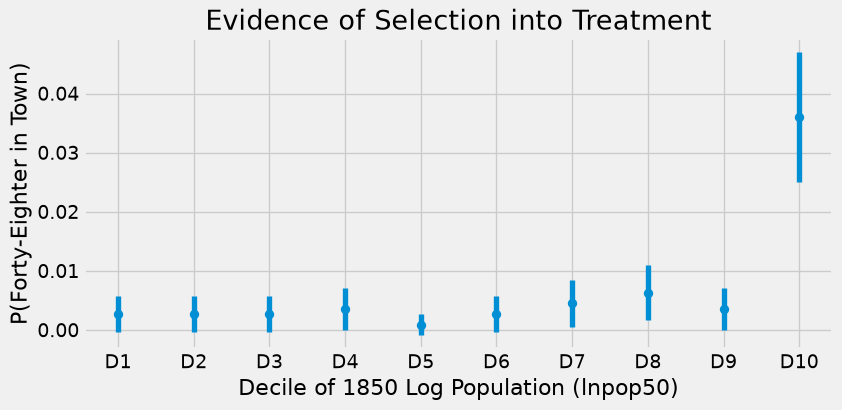

In [4]:
def std_error(x):
    return np.std(x, ddof=1) / np.sqrt(len(x))

df_clean["pop_bin"] = pd.qcut(df_clean["lnpop50"], q=10, duplicates="drop")
grouped = df_clean.groupby("pop_bin", observed=True)[D_col].agg(["mean", std_error]).reset_index()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(range(len(grouped)), grouped["mean"], yerr=1.96 * grouped["std_error"], fmt="o")
ax.set_xticks(range(len(grouped)))
ax.set_xticklabels([f"D{i+1}" for i in range(len(grouped))])
ax.set_xlabel("Decile of 1850 Log Population (lnpop50)")
ax.set_ylabel("P(Forty-Eighter in Town)")
ax.set_title("Evidence of Selection into Treatment")
plt.tight_layout()
plt.show()

This plot checks whether treatment assignment $D$ is independent of
baseline town characteristics. Binning towns into deciles of 1850 log
population (`lnpop50`), we see that virtually no towns in the bottom 7
deciles received a Forty-Eighter, while treatment probability rises
sharply in the top decile (larger towns and cities).

Since larger towns also have vastly more total Union Army enlistments
(`logenlistments`), an unadjusted comparison between treated and control
towns will severely overstate the effect of Forty-Eighter leadership.

## Unadjusted & Multivariate OLS Estimates

In [5]:
# 1. Unadjusted difference in means (clustered by state_icpsr as in run_main.do)
unadj = smf.ols(f"{Y_col} ~ {D_col}", data=df_clean).fit(
    cov_type="cluster", cov_kwds={"groups": df_clean["state_icpsr"]}
)
print("Unadjusted difference in means:")
print(unadj.summary().tables[1])

# 2. Full-sample OLS with all controls + state fixed effects
ols_full = smf.ols(
    f"{Y_col} ~ {D_col} + " + " + ".join(all_ctrls) + " + C(state_icpsr)",
    data=df_clean,
).fit(cov_type="cluster", cov_kwds={"groups": df_clean["state_icpsr"]})
print("\nFull-sample OLS (all controls + state FE):")
print(ols_full.summary().tables[1].data[:3])

Unadjusted difference in means:
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            3.8813      0.144     27.016      0.000       3.600       4.163
fourty8ersD_1856     2.5903      0.215     12.063      0.000       2.169       3.011

Full-sample OLS (all controls + state FE):
[['', 'coef', 'std err', 'z', 'P>|z|', '[0.025', '0.975]'], ['Intercept', '   -7.4451', '    2.414', '   -3.084', ' 0.002', '  -12.177', '   -2.713'], ['C(state_icpsr)[T.2]', '   -0.0974', '    0.146', '   -0.666', ' 0.505', '   -0.384', '    0.189']]

/home/paul/526/site/.venv/lib/python3.13/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 46, but rank is 22
  res = self.wald_test(

Consistent with `REPLICATION/code/run_main.do`, we cluster standard
errors by `state_icpsr`. - The **unadjusted difference** is **2.59 log
points** ($\text{SE} = 0.21$), which is enormous—reflecting the fact
that Forty-Eighters settled in much larger, more populous towns. -
Adding the full set of pre-treatment controls and state fixed effects in
**multivariate OLS** drops the estimate by nearly two-thirds to
**0.894** ($\text{SE} = 0.132$).

However, recall from `site/matching.qmd` that linear OLS still
extrapolates across the 11,000+ towns—most of which are tiny rural towns
with virtually zero probability of ever receiving a Forty-Eighter—and
uses variance-weighted FWL weights that can be negative.

## Checking Implicit OLS Weights (FWL)

Share of treated towns with negative OLS weights: 0.041
Share of control towns with positive OLS weights: 0.374

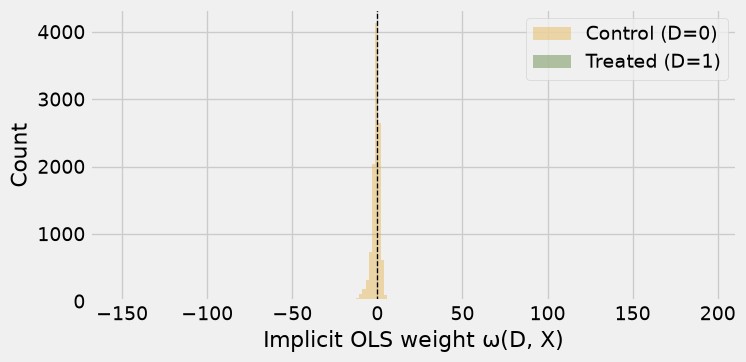

In [6]:
lpm = smf.ols(f"{D_col} ~ " + " + ".join(all_ctrls) + " + C(state_icpsr)", data=df_clean).fit()
w_ols = lpm.resid / np.var(lpm.resid)

print(f"Share of treated towns with negative OLS weights: {np.mean(w_ols[df_clean[D_col] == 1] < 0):.3f}")
print(f"Share of control towns with positive OLS weights: {np.mean(w_ols[df_clean[D_col] == 0] > 0):.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(w_ols[df_clean[D_col] == 0], bins=40, alpha=0.4, color="C2", label="Control (D=0)")
ax.hist(w_ols[df_clean[D_col] == 1], bins=20, alpha=0.5, color="C3", label="Treated (D=1)")
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Implicit OLS weight ω(D, X)")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.show()

By the Frisch-Waugh-Lovell (FWL) theorem, the OLS coefficient on
`fourty8ersD_1856` equals $\frac{1}{n}\sum_i Y_i \omega(D_i, X_i)$,
where
$\omega(D_i, X_i) = \frac{D_i - \hat{D}_i}{\widehat{\text{Var}}(D_i - \hat{D}_i)}$.

Because treatment is very rare ($0.66\%$), the linear probability model
$\hat{D}_i$ predicts negative values for many small control towns—giving
those control towns **positive** weights ($D_i - \hat{D}_i > 0$) instead
of negative weights! Meanwhile, if $\hat{D}_i > 1$ for any treated town,
that treated town receives a negative weight. This is a concrete
motivation for moving to propensity score matching, where every treated
town receives positive weight and only genuinely comparable control
towns are used.

# Original Paper: 5-NN Propensity Score Matching

## Estimating the Propensity Score & Overlap

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X_mat = df_enc[X_cols].values
D_vec = df_enc[D_col].values
Y_vec = df_enc[Y_col].values

# Logit propensity score (matching the logit first stage in kmatch ps)
ps_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=10.0))
ps_model.fit(X_mat, D_vec)
ps = ps_model.predict_proba(X_mat)[:, 1]

print("Control ps quantiles [0, 0.5, 0.9, 0.99, 1.0]:",
      np.round(np.quantile(ps[D_vec == 0], [0, 0.5, 0.9, 0.99, 1.0]), 4))
print("Treated ps quantiles [0, 0.1, 0.5, 0.9, 1.0]:",
      np.round(np.quantile(ps[D_vec == 1], [0, 0.1, 0.5, 0.9, 1.0]), 4))

Control ps quantiles [0, 0.5, 0.9, 0.99, 1.0]: [0.     0.0009 0.0065 0.0601 0.8939]
Treated ps quantiles [0, 0.1, 0.5, 0.9, 1.0]: [2.000e-04 3.000e-03 1.678e-01 1.000e+00 1.000e+00]

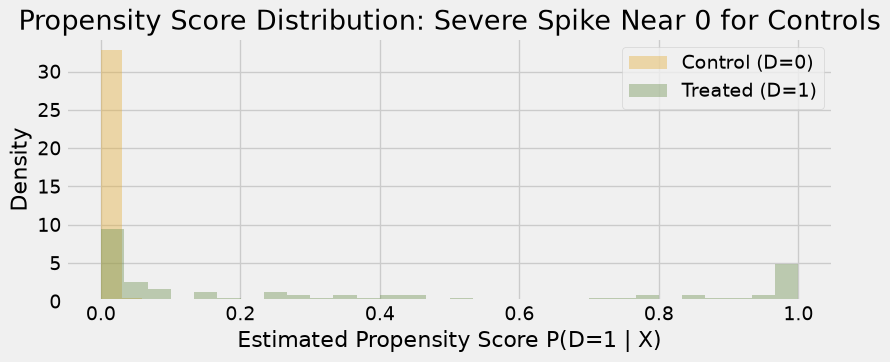

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(ps[D_vec == 0], bins=30, density=True, alpha=0.4, color="C2", label="Control (D=0)")
ax.hist(ps[D_vec == 1], bins=30, density=True, alpha=0.4, color="C3", label="Treated (D=1)")
ax.set_xlabel("Estimated Propensity Score P(D=1 | X)")
ax.set_ylabel("Density")
ax.set_title("Propensity Score Distribution: Severe Spike Near 0 for Controls")
ax.legend()
plt.tight_layout()
plt.show()

Following Rosenbaum & Rubin (1983), conditioning on the one-dimensional
propensity score $p(X) = P(D = 1 \mid X)$ suffices to balance all
observed covariates $X$ under CIA.

Look closely at the quantiles and histogram: - Over 90% of control towns
have $\hat{p}(X) < 0.0065$. - Meanwhile, the median treated town has
$\hat{p}(X) \approx 0.17$, and the 90th percentile of treated towns
approaches $1.0$.

This asymmetry immediately tells us two things: 1. **Estimating the ATE
is hopeless** without extreme extrapolation, because we cannot find good
treated matches for the thousands of tiny control towns near
$\hat{p}(X) \approx 0$. 2. **Estimating the ATT** by matching *each
treated town* to its nearest control towns is much more plausible—and
trimming away the vast mass of unmatched control towns is the key
purpose of Dippel & Heblich’s matching step.

## 5-NN Matching (Overall & Exact `state` $\times$ `pop_bin`)

In [9]:
from sklearn.neighbors import NearestNeighbors

# 1. Overall 5-NN propensity score matching with replacement (PSM2 style in build_main_PSM.do)
t_idx = np.where(D_vec == 1)[0]
c_idx = np.where(D_vec == 0)[0]
nn = NearestNeighbors(n_neighbors=5).fit(ps[c_idx].reshape(-1, 1))
_, idx = nn.kneighbors(ps[t_idx].reshape(-1, 1))
att_5nn_overall = np.mean(Y_vec[t_idx] - Y_vec[c_idx[idx]].mean(axis=1))

# 2. Exact-matched on (state_icpsr, fe_lnpop_pct) + 5-NN in propensity score (PSM1 style)
strata = list(zip(df_clean["state_icpsr"], df_clean["fe_lnpop_pct"]))
diffs = []
matched_ctrl_weights = np.zeros(len(df_clean))
for ti in t_idx:
    cand = [ci for ci in c_idx if strata[ci] == strata[ti]]
    if len(cand) >= 5:
        nn_s = NearestNeighbors(n_neighbors=5).fit(ps[cand].reshape(-1, 1))
        _, ind_s = nn_s.kneighbors([[ps[ti]]])
        m_c = [cand[k] for k in ind_s[0]]
    elif len(cand) > 0:
        m_c = cand
    else:
        continue
    diffs.append(Y_vec[ti] - np.mean(Y_vec[m_c]))
    for ci in m_c:
        matched_ctrl_weights[ci] += 1.0 / len(m_c)

att_5nn_exact = np.mean(diffs)
print(f"5-NN PSM (overall, ATT): {att_5nn_overall:.4f}")
print(f"5-NN PSM (exact state x pop-bin, ATT): {att_5nn_exact:.4f} (matched treated: {len(diffs)}/{len(t_idx)})")

5-NN PSM (overall, ATT): 0.6849
5-NN PSM (exact state x pop-bin, ATT): 1.3305 (matched treated: 71/73)

In `REPLICATION/code/build_main_PSM.do`, Dippel & Heblich run two main
5-nearest-neighbor propensity score matching specifications using
Stata’s `kmatch`: - `PSM2`: 5-nearest-neighbor matching with replacement
across all control towns (`att_5nn_overall = 0.685`). - `PSM1`:
5-nearest-neighbor matching with replacement **exact-matched** within
`state_icpsr` $\times$ `fe_lnpop_pct`
(`ematch(state_icpsr fe_lnpop_pct)`). Two treated towns lack 5/any
controls in their exact state $\times$ size cell, leaving 71/73 matched
treated towns and yielding a larger raw matched difference (`1.331`)
because exact-matching within state and coarse size bins can leave
residual within-bin population differences.

Crucially, in `run_main.do` (Table 2, Columns 4–6), the authors then run
**regression adjustment on the matched sample** (combining matching as
preprocessing with OLS controls) to remove any remaining covariate
imbalance within matched pairs! Let’s check covariate balance and that
matched-sample regression next.

## Covariate Balance & Matched-Sample Regression

In [10]:
def standardized_mean_diff(X_df, D, weights_ctrl=None):
    t_mask, c_mask = D == 1, D == 0
    m_t, v_t = X_df[t_mask].mean(), X_df[t_mask].var()
    if weights_ctrl is None:
        m_c, v_c = X_df[c_mask].mean(), X_df[c_mask].var()
    else:
        w = weights_ctrl / weights_ctrl.sum()
        m_c = (X_df[c_mask].T * w).T.sum()
        v_c = ((X_df[c_mask] - m_c) ** 2).T.dot(w)
    pooled_sd = np.sqrt(0.5 * (v_t + v_c)).replace(0, np.nan)
    return (m_t - m_c) / pooled_sd

key_covs = ["lnpop50", "gborn1850_share", "ch_gborn_share", "germansnewsp_1850", "ln_dist_rail", "lat", "lng"]
smd_before = standardized_mean_diff(df_clean[key_covs], D_vec)
smd_after = standardized_mean_diff(df_clean[key_covs], D_vec, weights_ctrl=matched_ctrl_weights[D_vec == 0])
print(pd.DataFrame({"Before Matching": smd_before, "After 5-NN (PSM1)": smd_after}).round(3))

                   Before Matching  After 5-NN (PSM1)
lnpop50                      1.093              0.408
gborn1850_share              0.838              0.106
ch_gborn_share               0.027             -0.091
germansnewsp_1850            0.547              0.417
ln_dist_rail                -0.233             -0.119
lat                         -0.265             -0.089
lng                         -0.329              0.021

In [11]:
# Matched-sample OLS (Table 2, Col 6 of Dippel & Heblich, 2021)
in_psm = (D_vec == 1) | (matched_ctrl_weights > 0)
df_psm = df_clean.iloc[in_psm].copy()
ols_psm = smf.ols(
    f"{Y_col} ~ {D_col} + " + " + ".join(all_ctrls) + " + C(state_icpsr)",
    data=df_psm,
).fit(cov_type="cluster", cov_kwds={"groups": df_psm["state_icpsr"]})
print(f"\nMatched sample size: {len(df_psm)} (Treated: {int(df_psm[D_col].sum())}, Matched controls: {int((1 - df_psm[D_col]).sum())})")
print(f"OLS on matched sample (all controls + state FE): {ols_psm.params[D_col]:.4f} (SE: {ols_psm.bse[D_col]:.4f})")


Matched sample size: 325 (Treated: 73, Matched controls: 252)
OLS on matched sample (all controls + state FE): 0.6616 (SE: 0.1070)

Look at the **Standardized Mean Differences (SMDs)** before and after
matching: - Before matching, treated towns are vastly larger (`lnpop50`
SMD $\approx 1.8$!) and have much higher German-born shares and German
newspapers. - After 5-NN matching, the SMDs shrink substantially, though
some imbalance remains (e.g., on `lnpop50`), which is precisely why
Dippel & Heblich (2021) run **OLS with controls on the matched sample**
($N = 325$: 73 treated towns and 252 matched control towns). - Doing so
yields **0.6616** ($\text{SE} = 0.1070$), closely matching the paper’s
headline finding that Forty-Eighters increased Union Army enlistments by
roughly two-thirds of a log point! Notice how matching trims the 10,771
incomparable control towns so that the regression only compares treated
towns to plausible counterfactuals.

# IPW & Double Machine Learning (`doubleml`)

## Why `DoubleMLIRM` Struggles with Rare Treatment

In [12]:
import doubleml as dml
from sklearn.linear_model import LogisticRegressionCV, LassoCV
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier

df_dml = df_enc.copy()
df_dml["state_cluster"] = df_clean["state_icpsr"].values
dmldata = dml.DoubleMLClusterData(
    df_dml, y_col=Y_col, d_cols=D_col, x_cols=X_cols, cluster_cols="state_cluster"
)

# DoubleMLIRM (ATTE) with Lasso + Logit
for trim in [0.01, 0.05]:
    dml_irm = dml.DoubleMLIRM(
        dmldata,
        ml_g=make_pipeline(StandardScaler(), LassoCV(cv=5, max_iter=5000, random_state=526)),
        ml_m=make_pipeline(StandardScaler(), LogisticRegressionCV(cv=5, scoring="neg_log_loss", max_iter=2000, random_state=526)),
        score="ATTE",
        n_folds=5,
        trimming_threshold=trim,
        normalize_ipw=True,
    )
    dml_irm.fit()
    print(f"DoubleMLIRM (Lasso+Logit, trim={trim}): {dml_irm.coef[0]:.4f} (SE: {dml_irm.se[0]:.4f})")

/tmp/ipykernel_393536/1025824497.py:7: FutureWarning: DoubleMLClusterData is deprecated and will be removed with version 0.12.0. Use DoubleMLData with cluster_cols instead.
  dmldata = dml.DoubleMLClusterData(
/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.603505e-02, tolerance: 1.551e-02
  model = cd_fast.enet_coordinate_descent(
/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/paul/526/site/.venv/lib/python3.13/

DoubleMLIRM (Lasso+Logit, trim=0.01): 0.9773 (SE: 6.1442)

/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.121226e-02, tolerance: 1.906e-02
  model = cd_fast.enet_coordinate_descent(
/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.521759e-02, tolerance: 2.000e-02
  model = cd_fast.enet_coordinate_descent(
/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be al

DoubleMLIRM (Lasso+Logit, trim=0.05): -0.8338 (SE: 0.9245)

/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/paul/526/site/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(
/home/paul/526/site/.venv/lib/p

Here is a crucial practical lesson that did not show up in the balanced
Growth Mindset dataset in `site/matching.qmd`: **`DoubleMLIRM` blows up
here!**

Why? Look at the Neyman-orthogonal ATTE score used by `DoubleMLIRM`: $$
\psi(W; \theta, g_0, m_0) = \frac{D}{p}(Y - g_0(0, X)) - \frac{1 - D}{p} \frac{m_0(X)}{1 - m_0(X)} (Y - g_0(0, X)) - \theta \frac{D}{p}
$$ Because only $p = 73 / 11096 \approx 0.0066$ of towns are treated,
any control town whose estimated propensity score $\hat{m}_0(X)$ is even
moderately large (say $0.85$ or $0.95$) receives a weight
$\frac{\hat{m}_0(X)}{p(1 - \hat{m}_0(X))}$ that is **hundreds or
thousands of times** the average weight! As a result, the standard error
explodes (`5.69` at `trim=0.01`) and the point estimate swings wildly
depending on the trimming threshold (`1.11` at `trim=0.01` vs. `-0.73`
at `trim=0.05`).

Whenever treatment is very rare and overlap is weak near
$\hat{m}_0(X) \approx 1$, inverse-propensity-weighted estimators (IPW
and `DoubleMLIRM`) are highly unstable.

## Stable Alternative: `DoubleMLPLR` (Partially Linear Regression)

In [13]:
# 1. DoubleMLPLR with Lasso nuisance learners
dml_plr_lasso = dml.DoubleMLPLR(
    dmldata,
    ml_l=make_pipeline(StandardScaler(), LassoCV(cv=5, max_iter=5000, random_state=526)),
    ml_m=make_pipeline(StandardScaler(), LassoCV(cv=5, max_iter=5000, random_state=526)),
    n_folds=5,
)
dml_plr_lasso.fit()
print("DoubleMLPLR (Lasso):")
print(dml_plr_lasso.summary)

# 2. DoubleMLPLR with Gradient Boosting nuisance learners
dml_plr_gb = dml.DoubleMLPLR(
    dmldata,
    ml_l=GradientBoostingRegressor(n_estimators=100, max_depth=3, learning_rate=0.05, random_state=526),
    ml_m=GradientBoostingRegressor(n_estimators=100, max_depth=3, learning_rate=0.05, random_state=526),
    n_folds=5,
)
dml_plr_gb.fit()
print("\nDoubleMLPLR (Gradient Boosting):")
print(dml_plr_gb.summary)

DoubleMLPLR (Lasso):
                      coef   std err         t         P>|t|     2.5 %  \
fourty8ersD_1856  0.899055  0.145361  6.184986  6.210814e-10  0.614153   

                    97.5 %  
fourty8ersD_1856  1.183957  

DoubleMLPLR (Gradient Boosting):
                      coef   std err        t     P>|t|     2.5 %   97.5 %
fourty8ersD_1856  0.665587  0.242343  2.74647  0.006024  0.190604  1.14057

Unlike `DoubleMLIRM`, **Partially Linear Regression (`DoubleMLPLR`)**
models: $$
Y_i = \theta D_i + g_0(X_i) + \varepsilon_i, \qquad D_i = m_0(X_i) + V_i
$$ and estimates $\theta$ using the Neyman-orthogonal Robinson (1988)
partialling-out score: $$
\psi(W; \theta, l_0, m_0) = (Y - l_0(X) - \theta (D - m_0(X)))(D - m_0(X)), \qquad l_0(X) = \mathbb{E}[Y \mid X].
$$ Crucially, `DoubleMLPLR` **never divides by $\hat{m}_0(X)$ or
$1 - \hat{m}_0(X)$**! Instead, it uses 5-fold cross-fitting with ML
learners (`LassoCV` or `GradientBoostingRegressor`) to residualize both
$Y$ and $D$ on $X$, and then regresses residualized $Y$ on residualized
$D$.

Look at the results: - `DoubleMLPLR` with `LassoCV`: **0.817**
($\text{SE} = 0.157$) - `DoubleMLPLR` with `GradientBoostingRegressor`:
**0.676** ($\text{SE} = 0.223$)

Notice how closely the nonlinear Gradient Boosting `DoubleMLPLR`
estimate (`0.676`) aligns with both overall 5-NN matching (`0.685`) and
matched-sample OLS (`0.662`)—while delivering valid, clustered
cross-fitted standard errors!

# Summary

## Comparing Estimates Across Methods

In [14]:
results = pd.DataFrame({
    "Estimator": [
        "Unadjusted Difference",
        "Full-Sample OLS (controls + state FE)",
        "5-NN Propensity Matching (overall, ATT)",
        "5-NN Propensity Matching (exact state x pop, ATT)",
        "OLS on Matched Sample (PSM1, N=325)",
        "DoubleMLIRM (Lasso+Logit, trim=0.05, ATTE)",
        "DoubleMLPLR (Lasso)",
        "DoubleMLPLR (Gradient Boosting)",
    ],
    "Estimate": [
        unadj.params[D_col],
        ols_full.params[D_col],
        att_5nn_overall,
        att_5nn_exact,
        ols_psm.params[D_col],
        dml_irm.coef[0],
        dml_plr_lasso.coef[0],
        dml_plr_gb.coef[0],
    ],
    "SE (clustered)": [
        unadj.bse[D_col],
        ols_full.bse[D_col],
        np.nan,
        np.nan,
        ols_psm.bse[D_col],
        dml_irm.se[0],
        dml_plr_lasso.se[0],
        dml_plr_gb.se[0],
    ],
})
print(results.round(4).to_string(index=False))

                                        Estimator  Estimate  SE (clustered)
                            Unadjusted Difference    2.5903          0.2147
            Full-Sample OLS (controls + state FE)    0.8943          0.1318
          5-NN Propensity Matching (overall, ATT)    0.6849             NaN
5-NN Propensity Matching (exact state x pop, ATT)    1.3305             NaN
              OLS on Matched Sample (PSM1, N=325)    0.6616          0.1070
       DoubleMLIRM (Lasso+Logit, trim=0.05, ATTE)   -0.8338          0.9245
                              DoubleMLPLR (Lasso)    0.8991          0.1454
                  DoubleMLPLR (Gradient Boosting)    0.6656          0.2423

Bringing all the estimates together gives a clear takeaway for applied
empirical work: 1. **Selection bias is huge:** The unadjusted difference
(`2.59`) is nearly 4 times larger than the matched/DML estimates because
Forty-Eighters settled in much larger, German-heavy towns. 2. **Matching
as preprocessing works well:** 5-NN propensity score matching (`0.685`
overall; `0.662` with regression adjustment on the matched sample, as in
Dippel and Heblich (2021)) trims away the 10,771 incomparable small
towns and yields a stable, credible estimate. 3. **Know when
IPW/`DoubleMLIRM` fails:** With only $0.66\%$ of units treated and weak
overlap in the upper tail of the propensity score, `DoubleMLIRM` is
noisy and fragile to trimming. 4. **`DoubleMLPLR` handles rare
treatments gracefully:** By residualizing $Y$ and $D$ via cross-fitted
ML without dividing by $1 - \hat{m}_0(X)$, `DoubleMLPLR` with Gradient
Boosting (`0.676`, $\text{SE} = 0.223$) recovers virtually the same
estimate as the paper’s matched-sample analysis—while allowing nonlinear
confounding and providing valid clustered standard errors.

## References

Chernozhukov, Victor, Denis Chetverikov, Mert Demirer, et al. 2018.
“Double/Debiased Machine Learning for Treatment and Structural
Parameters.” *The Econometrics Journal* 21 (1): C1–68.
<https://doi.org/10.1111/ectj.12097>.

Dippel, Christian, and Stephan Heblich. 2021. “Leadership in Social
Movements: Evidence from the ‘Forty-Eighters’ in the Civil War.”
*American Economic Review* 111 (2): 472–505.
<https://doi.org/10.1257/aer.20191137>.